# TRSP Thesis Figures
Generates the three figures for section 6.5.3 (Testing Results) of the thesis.
Outputs saved to `results/figures/`.

| Figure | File | Description |
|--------|------|-------------|
| 1 | `psl_agent_comparison.png` | PSL agents × networks, mean over K=1–4 |
| 2 | `effect_of_k.png` | K-effect on makespan + success, mean over networks |
| 3 | `svc_agent_comparison.png` | SVC agents × networks |

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# serif fonts to match LaTeX output
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

BASE = Path('..').resolve()
RUNS = BASE / 'runs' / 'trsp'
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Base:', BASE)
print('Figures will be saved to:', FIG_DIR)

Base: /home/shinobi-owl/PhD/battery/DroneSim
Figures will be saved to: /home/shinobi-owl/PhD/battery/DroneSim/results/figures


## Constants

In [2]:
NET_ORDER = ['Grid', 'Rand-Grid', 'Ames']

PSL_ALGO_ORDER  = ['SSP', 'SARSA', 'DQN', 'PPO', 'A2C']
PSL_ALGO_COLORS = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b3']

SVC_ALGO_ORDER  = ['SSP', 'DSP', 'SARSA-SVC', 'DQN-SVC', 'A2C-SVC', 'PPO-SVC']
SVC_ALGO_COLORS = ['#4c72b0', '#937860', '#dd8452', '#55a868', '#8172b3', '#c44e52']

# line styles for K-effect plot
K_STYLES = {
    'SSP':   ('-',  'o', '#4c72b0'),
    'SARSA': ('-',  's', '#dd8452'),
    'DQN':   ('-',  '^', '#55a868'),
    'PPO':   ('--', 'D', '#c44e52'),
    'A2C':   ('--', 'v', '#8172b3'),
}

## Load Data

In [3]:
df_raw = pd.read_csv(BASE / 'results' / 'trsp_results.csv')

net_map = {'N1': 'Grid', 'N2': 'Rand-Grid', 'N3': 'Ames'}

# PSL rows (traffic T1–T4)
df_psl = df_raw[df_raw['traffic'].str.startswith('T')].copy()
df_psl['network']     = df_psl['network'].map(net_map)
df_psl['K']           = df_psl['traffic'].str[1].astype(int)
df_psl['agent']       = df_psl['algo'].map({'dijkstra': 'SSP', 'sarsa': 'SARSA',
                                             'dqn': 'DQN', 'ppo': 'PPO', 'a2c': 'A2C'})
df_psl['success_pct'] = df_psl['success_rate'] * 100

# SVC rows
df_svc = df_raw[df_raw['traffic'].str.startswith('SVC')].copy()
df_svc['network']     = df_svc['network'].map(net_map)
df_svc['agent']       = df_svc['algo'].map({'dijkstra': 'SSP', 'dsp': 'DSP',
                                             'sarsa_svc': 'SARSA-SVC', 'dqn_svc': 'DQN-SVC',
                                             'a2c_svc': 'A2C-SVC', 'ppo_svc': 'PPO-SVC'})
df_svc['success_pct'] = df_svc['success_rate'] * 100

print(f'PSL rows: {len(df_psl)}  |  SVC rows: {len(df_svc)}')
print('PSL agents:', df_psl['agent'].dropna().unique().tolist())
print('SVC agents:', df_svc['agent'].dropna().unique().tolist())

PSL rows: 60  |  SVC rows: 18
PSL agents: ['DQN', 'PPO', 'A2C', 'SSP', 'SARSA']
SVC agents: ['DQN-SVC', 'A2C-SVC', 'PPO-SVC', 'SSP', 'DSP', 'SARSA-SVC']


## Figure 1 — PSL Agent Comparison (mean over K=1–4)

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/psl_agent_comparison.png


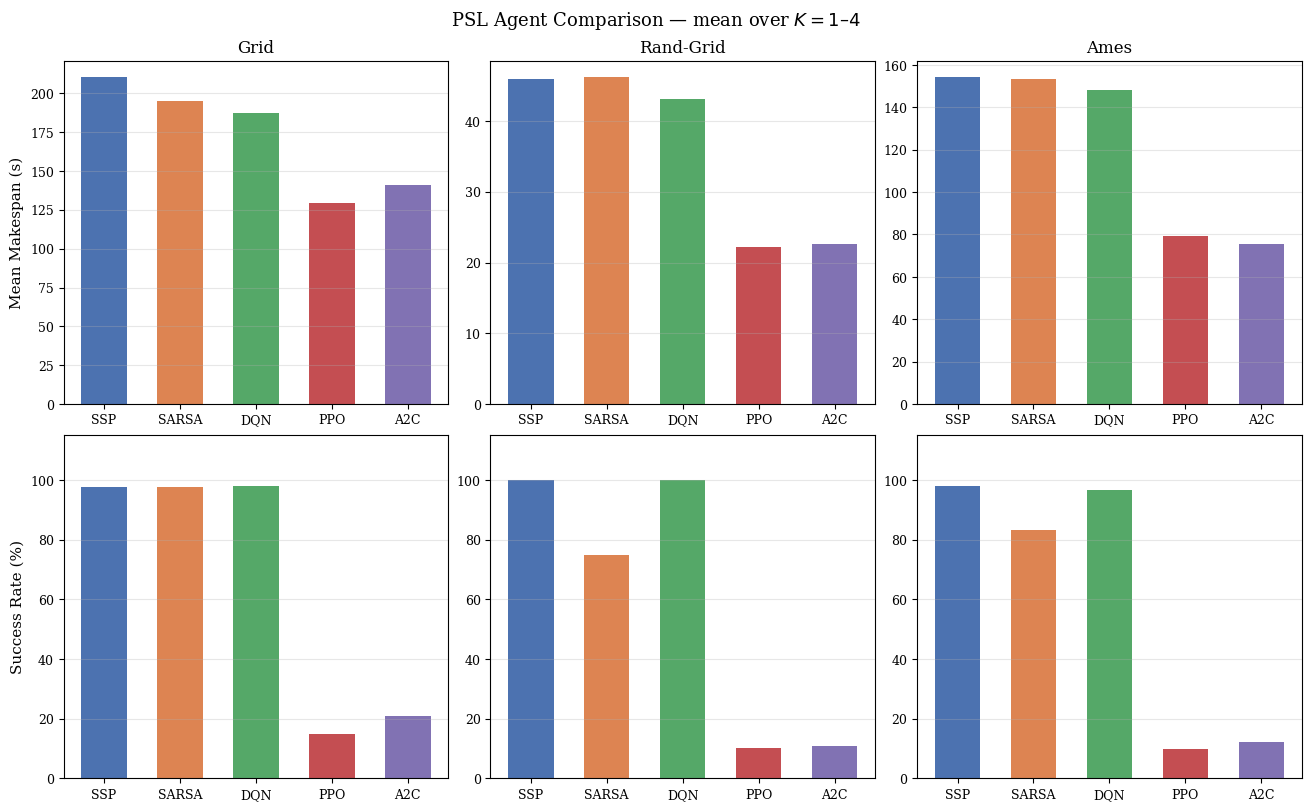

In [4]:
psl_avg = df_psl.groupby(['network', 'agent'])[['makespan_mean', 'success_pct']].mean().reset_index()

x     = np.arange(len(PSL_ALGO_ORDER))
width = 0.6

fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
fig.suptitle('PSL Agent Comparison — mean over $K = 1$–$4$', fontsize=13)

for col, net in enumerate(NET_ORDER):
    sub = psl_avg[psl_avg['network'] == net].set_index('agent')

    ax = axes[0, col]
    vals = [sub.loc[a, 'makespan_mean'] if a in sub.index else np.nan for a in PSL_ALGO_ORDER]
    ax.bar(x, vals, width, color=PSL_ALGO_COLORS)
    ax.set_title(net, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(PSL_ALGO_ORDER)
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

    ax = axes[1, col]
    vals = [sub.loc[a, 'success_pct'] if a in sub.index else np.nan for a in PSL_ALGO_ORDER]
    ax.bar(x, vals, width, color=PSL_ALGO_COLORS)
    ax.set_xticks(x); ax.set_xticklabels(PSL_ALGO_ORDER)
    ax.set_ylim(0, 115)
    if col == 0: ax.set_ylabel('Success Rate (%)')
    ax.grid(True, axis='y', alpha=0.3)

out = FIG_DIR / 'psl_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 2 — Effect of K (mean over all networks)

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/effect_of_k.png


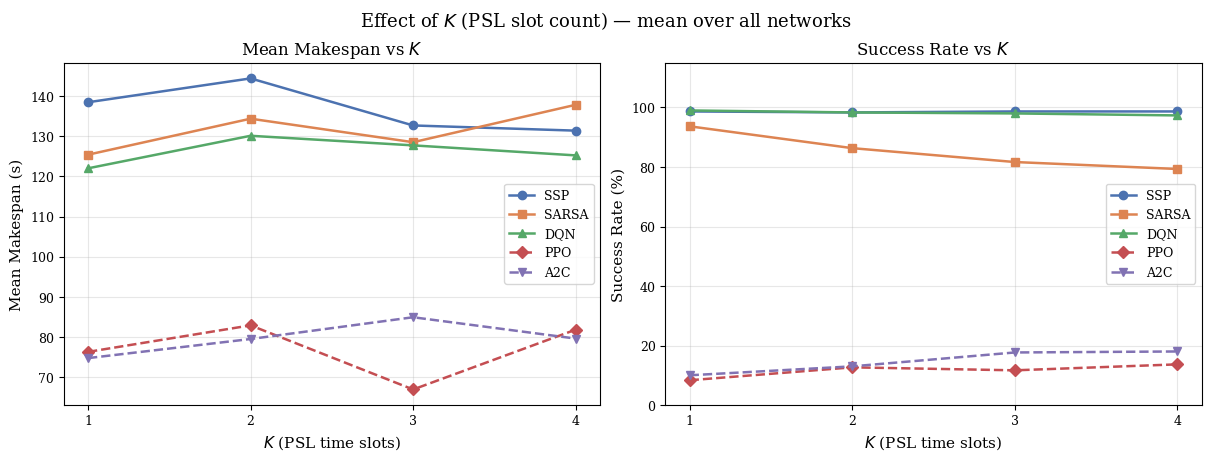

In [5]:
k_avg = df_psl.groupby(['K', 'agent'])[['makespan_mean', 'success_pct']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
fig.suptitle('Effect of $K$ (PSL slot count) — mean over all networks', fontsize=13)

for algo in PSL_ALGO_ORDER:
    ls, marker, color = K_STYLES[algo]
    sub = k_avg[k_avg['agent'] == algo].sort_values('K')
    axes[0].plot(sub['K'], sub['makespan_mean'], linestyle=ls, marker=marker,
                 color=color, label=algo, linewidth=1.8, markersize=6)
    axes[1].plot(sub['K'], sub['success_pct'],   linestyle=ls, marker=marker,
                 color=color, label=algo, linewidth=1.8, markersize=6)

for ax, ylabel, title in zip(axes,
        ['Mean Makespan (s)', 'Success Rate (%)'],
        ['Mean Makespan vs $K$', 'Success Rate vs $K$']):
    ax.set_xlabel('$K$ (PSL time slots)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks([1, 2, 3, 4])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
axes[1].set_ylim(0, 115)

out = FIG_DIR / 'effect_of_k.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 3 — SVC Agent Comparison

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/svc_agent_comparison.png


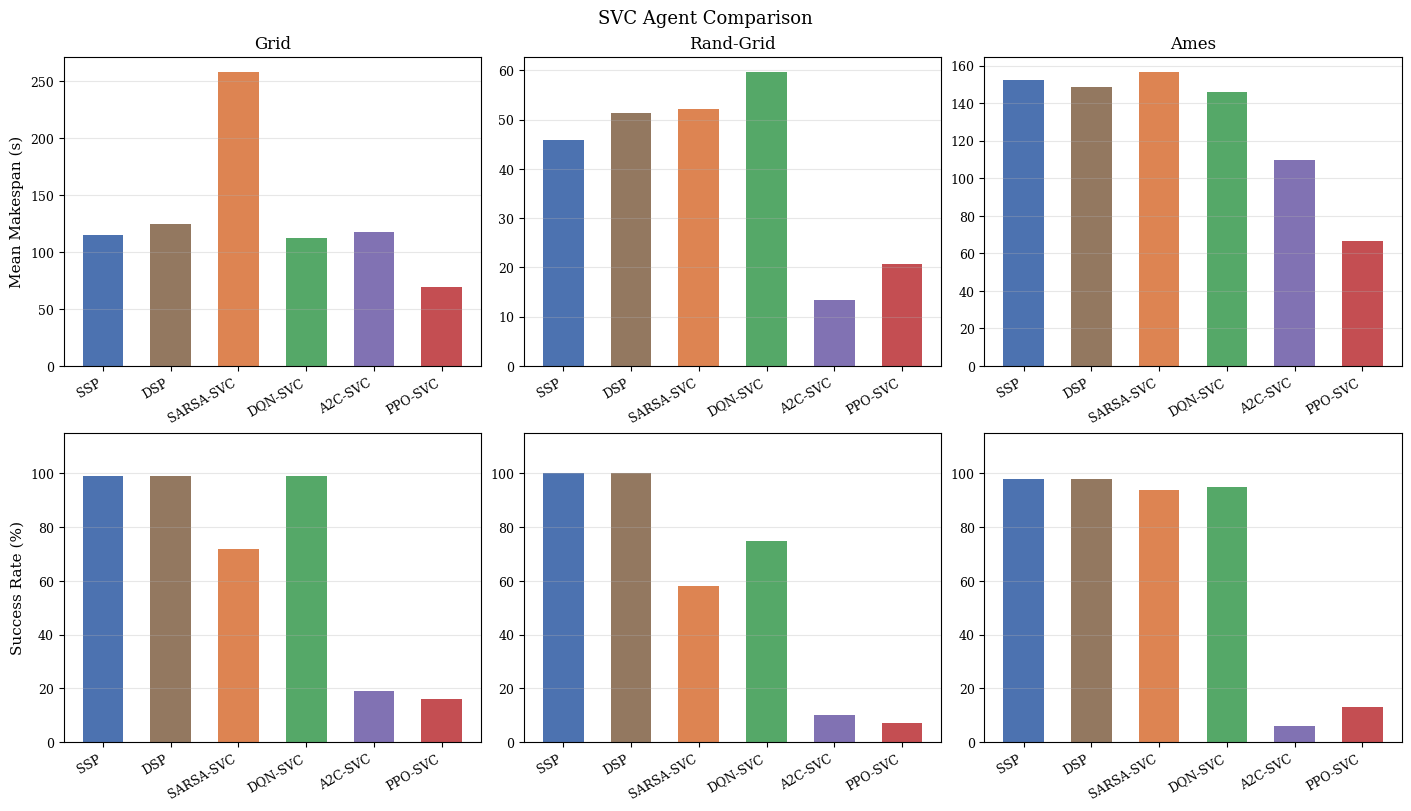

In [6]:
x     = np.arange(len(SVC_ALGO_ORDER))
width = 0.6

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
fig.suptitle('SVC Agent Comparison', fontsize=13)

for col, net in enumerate(NET_ORDER):
    sub = df_svc[df_svc['network'] == net].set_index('agent')

    ax = axes[0, col]
    vals = [sub.loc[a, 'makespan_mean'] if a in sub.index else np.nan for a in SVC_ALGO_ORDER]
    ax.bar(x, vals, width, color=SVC_ALGO_COLORS)
    ax.set_title(net, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(SVC_ALGO_ORDER, rotation=30, ha='right')
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

    ax = axes[1, col]
    vals = [sub.loc[a, 'success_pct'] if a in sub.index else np.nan for a in SVC_ALGO_ORDER]
    ax.bar(x, vals, width, color=SVC_ALGO_COLORS)
    ax.set_xticks(x); ax.set_xticklabels(SVC_ALGO_ORDER, rotation=30, ha='right')
    ax.set_ylim(0, 115)
    if col == 0: ax.set_ylabel('Success Rate (%)')
    ax.grid(True, axis='y', alpha=0.3)

out = FIG_DIR / 'svc_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()